In [1]:
import matplotlib.pyplot as plt
import contextily as cx
import cv2

from datetime import datetime, timedelta
import os
import pandas as pd
import numpy as np

import geopandas
from cartopy import crs as ccrs
from geodatasets import get_path

In [2]:
from matplotlib.backends.backend_agg import FigureCanvasAgg

1. Datasets

In [66]:
#1. import dataset

nasa_df = pd.read_csv("../dataset/nasa/final_dataset/nasa_final.csv")

essential_df = nasa_df[['latitude', 'longitude', 'acq_date', 'acq_time', 'frp']].copy()
essential_df

# 2. convert latitude, longitude values into point geometry
geo_essential_df = geopandas.GeoDataFrame(
    essential_df, geometry=geopandas.points_from_xy(essential_df.longitude, essential_df.latitude), crs="EPSG:4326"
)

# show top 3 records
geo_essential_df.head(3)


C:\Users\ASUS\AppData\Local\Temp\ipykernel_17628\2449856852.py:3: DtypeWarning: Columns (10: version) have mixed types. Specify dtype option on import or set low_memory=False.
  nasa_df = pd.read_csv("../dataset/nasa/final_dataset/nasa_final.csv")


,latitude,longitude,acq_date,acq_time,frp,geometry
0,-6.32139,138.67276,2026-01-01,352,7.55,POINT (138.67276 -6.32139)
1,-2.74199,132.94307,2026-01-01,353,46.30,POINT (132.94307 -2.74199)
2,-2.72553,132.93201,2026-01-01,353,6.35,POINT (132.93201 -2.72553)


In [67]:
import matplotlib.pyplot as plt
import geopandas as gpd
import contextily as cx

# 1. Load high-res Indonesia borders
url = "https://naciscdn.org/naturalearth/10m/cultural/ne_10m_admin_0_countries.zip"
world = gpd.read_file(url).rename(columns={'ADMIN': 'name'})
indonesia = world[world['name'] == 'Indonesia']

indonesia

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,name,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
0,Admin-0 country,0,2,Indonesia,IDN,0,2,Sovereign country,1,Indonesia,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((117.70361 4.16341, 117.70361 4..."


In [68]:
import geopandas as gpd

# Download once from the web
url = "https://naciscdn.org/naturalearth/10m/cultural/ne_10m_admin_0_countries.zip"
world = gpd.read_file(url)

# Save it locally into your project folder as a GeoJSON file
world.to_file("../map/world_highres.geojson", driver="GeoJSON")
print("Saved locally successfully!")

Saved locally successfully!


2. The actual thing

In [69]:
#1. load country borders
world = gpd.read_file("../map/country_borders_highres.geojson")
world = world.rename(columns={'ADMIN': 'name'})
indonesia = world[world['name'] == 'Indonesia'] #geopanda dataframe

# 2. Recomputes coordinates to Web Mercator (wm) Projection (EPSG:3857)
indonesia_wm = indonesia.to_crs(epsg=3857) #from the world map
geo_essential_df_wm = geo_essential_df.to_crs(epsg=3857) #from the nasa dataset


NASA data and the Indonesia shapes came in as latitude/longitude, which is called EPSG:4326. Those numbers are degrees, like 106.8 east and -6.2 south for Jakarta. EPSG:3857 is Web Mercator (Web Mercator Projection for maps), which expresses positions as meters on a flat map (Jakarta becomes something like x = 11,900,000 and y = -690,000). to_crs takes every point in the geometry column (from converted dataset) and recomputes it in the new system. It returns a new GeoDataFrame, which is why you assign it to a new variable.

In [131]:
# 3. Convert date to a single datetime object
geo_essential_df_wm['datetime'] = pd.to_datetime(geo_essential_df_wm['acq_date'], format='%Y-%m-%d')

geo_essential_df_wm.head(3)


,latitude,longitude,acq_date,acq_time,frp,geometry,datetime
0,-6.32139,138.67276,2026-01-01,0352,7.55,POINT (15436981.03 -705125.895),2026-01-01
1,-2.74199,132.94307,2026-01-01,0353,46.30,POINT (14799154.857 -305353.51),2026-01-01
2,-2.72553,132.93201,2026-01-01,0353,6.35,POINT (14797923.663 -303519.103),2026-01-01


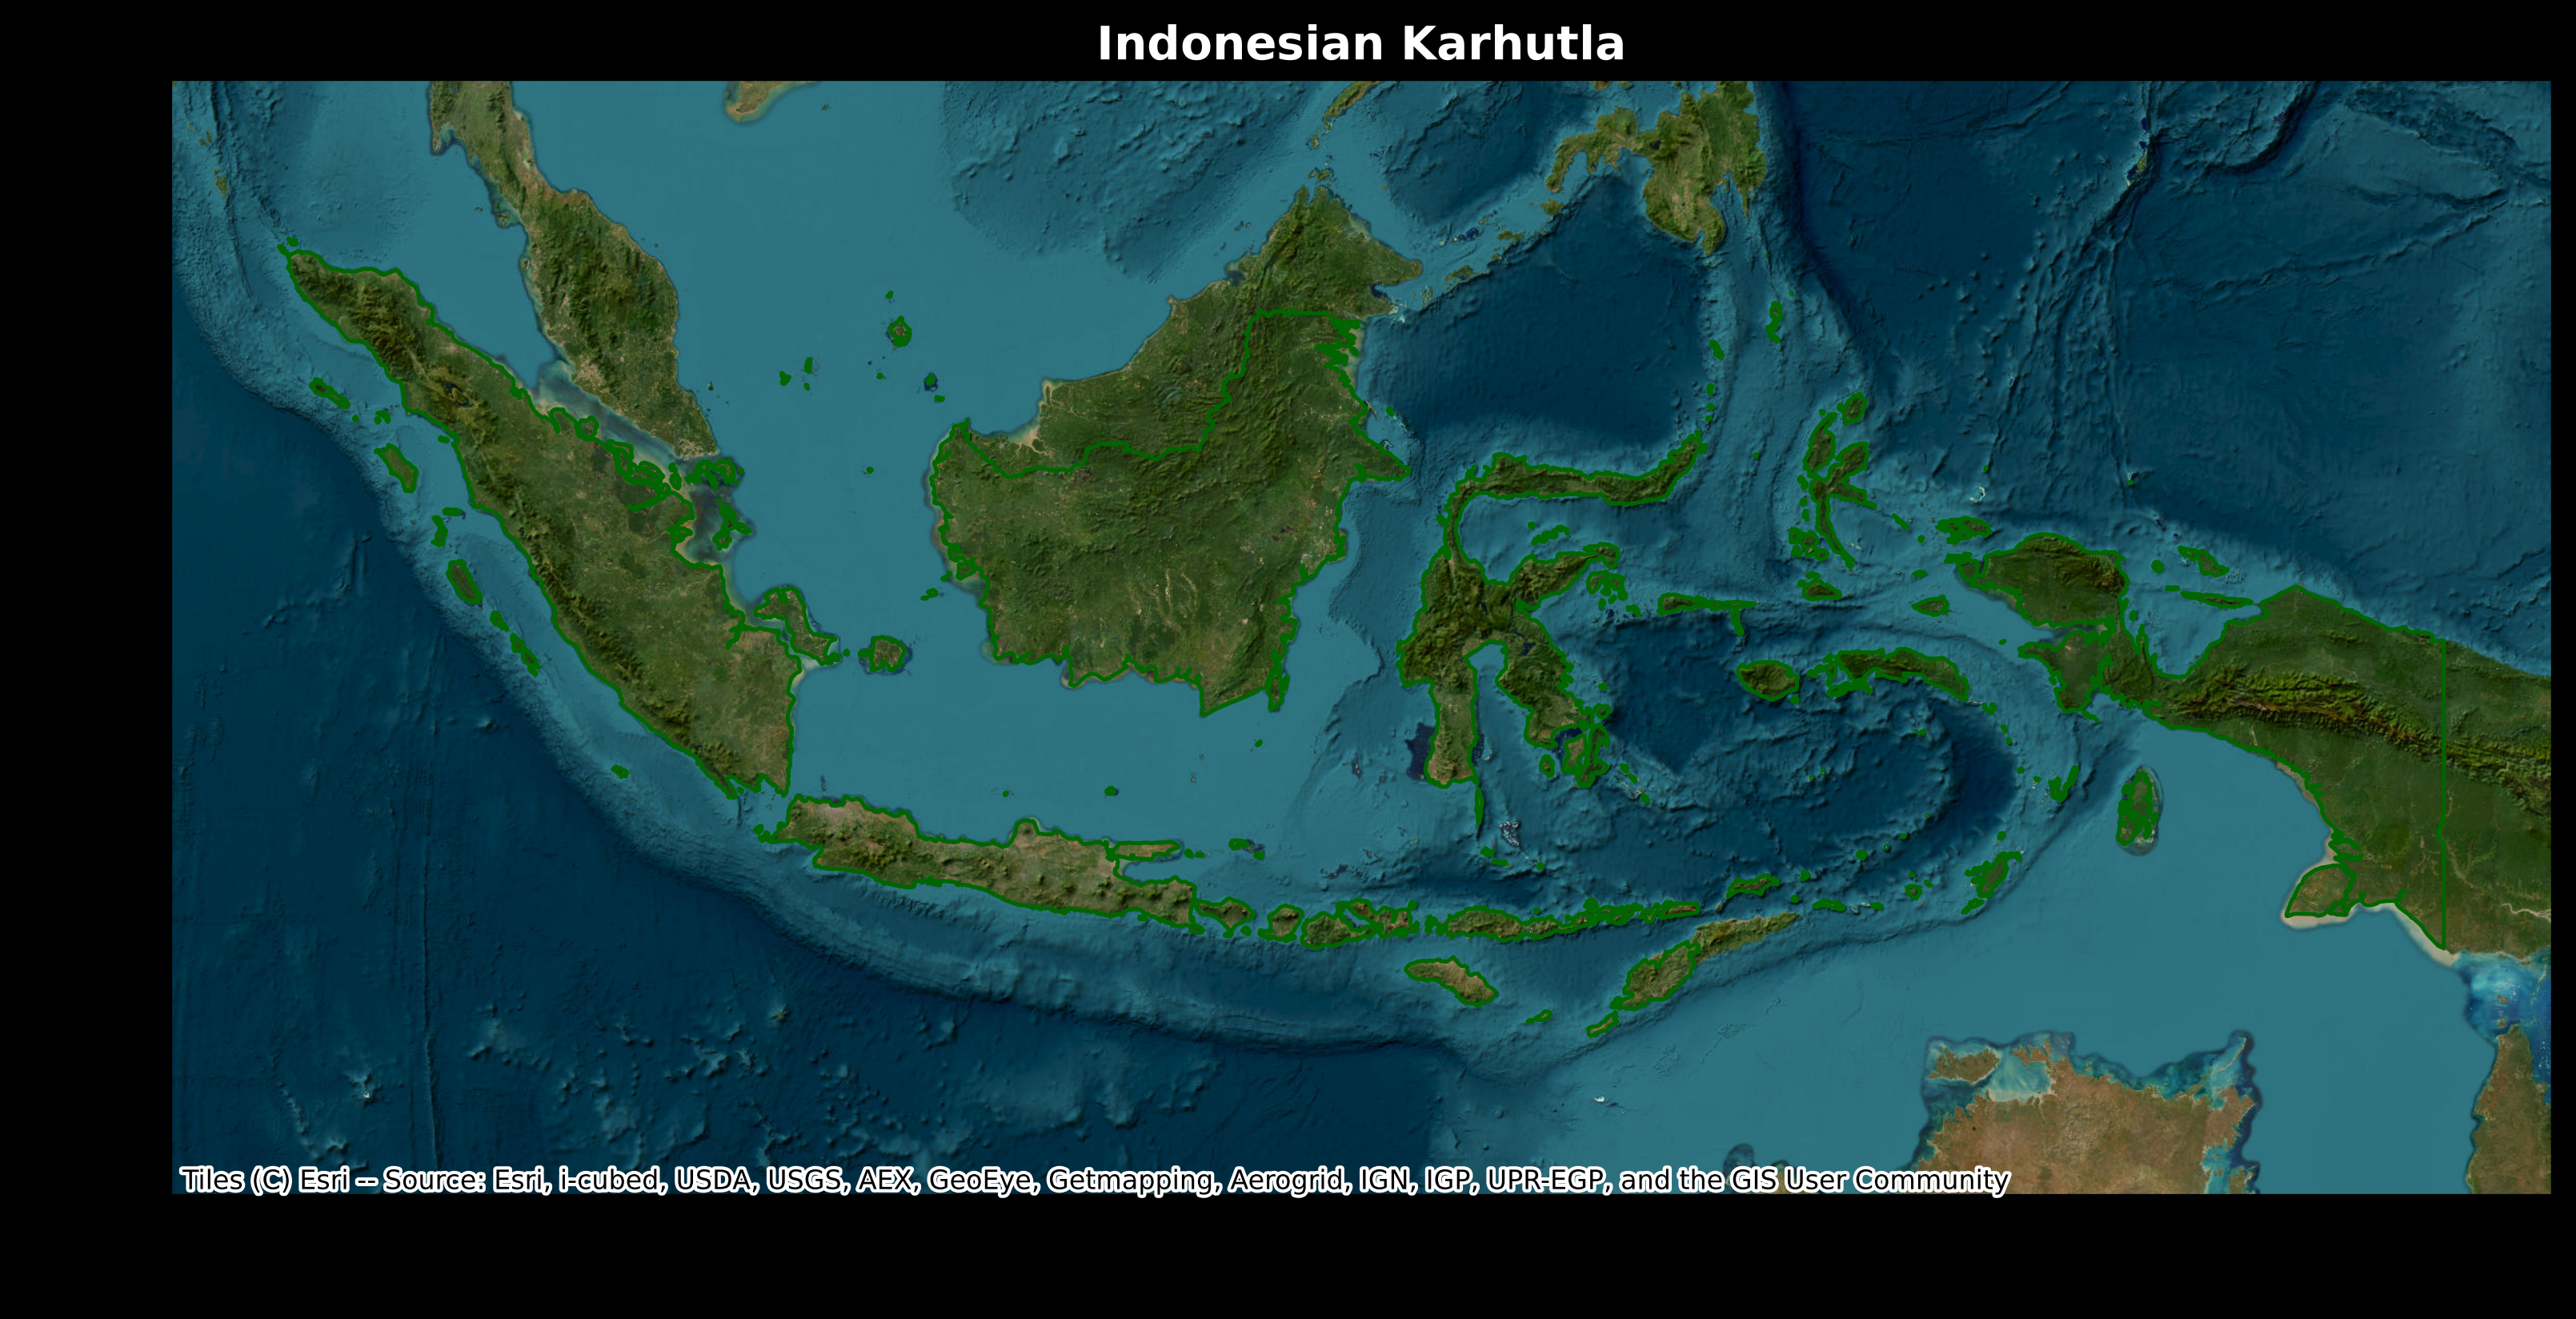

In [133]:
#RAN ONCE

# 3. Set up figure and axes first before painting anything
fig, ax = plt.subplots(figsize=(12.8, 7.2), dpi=300) 

canvas = FigureCanvasAgg(fig)

# set up limit for axes
xmin, ymin, xmax, ymax = indonesia_wm.total_bounds

# note:
# indonesia_wm: Represents a GeoDataFrame containing spatial data for Indonesia,
# .total_bounds: A GeoPandas attribute that calculates the minimum and maximum coordinates of the entire dataset's bounding box.

# Expand the boundary (add 20% more height, 5% more width)
height_buffer = (ymax - ymin) * 0.20
width_buffer = (xmax - xmin) * 0.05
xmax_extended = xmax + width_buffer
xmin_extended = xmin - width_buffer
ymax_extended = ymax + height_buffer
ymin_extended = ymin - height_buffer

# 3. Before anything, explicitly initialize the view limit for axes first
# Force bounds with the extended top
ax.set_xlim([xmin_extended, xmax_extended])
ax.set_ylim([ymin_extended, ymax_extended])

# 4. Load and paint base map with contextily (cx) (Esri Satellite Imagery Basemap)
# Note: ax signify the basemap is painted to "ax" axes
cx.add_basemap(
    ax, 
    source=cx.providers.Esri.WorldImagery,
    headers={'User-Agent': 'KarhutlaMappingProject/1.0'},
    zoom=6
)

# 5. going back to the country borders earlier
# Paint Indonesia outline
indonesia_wm.plot(ax=ax, color="none", edgecolor="darkgreen", linewidth=1.2, zorder=3)

# 6. set title and everything rendered outside the axes
ax.set_title("Indonesian Karhutla", fontsize=14, fontweight='bold', color='white')
fig.patch.set_facecolor('black') # Makes the window frame dark

In [161]:
# INITIALIZE cv2 VideoWriter

# 1. Define video parameters
#make sure the directory exist
os.makedirs("../output/video_output/full_id", exist_ok=True)
output_filename = '../output/video_output/full_id/full_12fps_id.mp4'
fps = 12
frame_size = (3840, 2160)  # Width, Height

# 2. Define the codec using FourCC
# Use *'mp4v' or *'XVID' for MP4/AVI containers
fourcc = cv2.VideoWriter_fourcc(*'mp4v') 

# 3. Initialize the VideoWriter
out = cv2.VideoWriter(output_filename, fourcc, fps, frame_size)

# Check if the video writer initialized successfully
if not out.isOpened():
    print("Error: Could not open the video writer.")
    exit()

In [162]:
unique_list = geo_essential_df_wm['datetime'].unique()
print(len(unique_list))
print(len(geo_essential_df_wm)) 

288
1569989


In [163]:
unique_list

<DatetimeArray>
['2026-01-01 00:00:00', '2026-01-02 00:00:00', '2026-01-03 00:00:00',
 '2026-01-04 00:00:00', '2026-01-05 00:00:00', '2026-01-06 00:00:00',
 '2026-01-07 00:00:00', '2026-01-08 00:00:00', '2026-01-09 00:00:00',
 '2026-01-10 00:00:00',
 ...
 '2026-10-06 00:00:00', '2026-10-07 00:00:00', '2026-10-08 00:00:00',
 '2026-10-09 00:00:00', '2026-10-10 00:00:00', '2026-10-11 00:00:00',
 '2026-10-12 00:00:00', '2026-10-13 00:00:00', '2026-10-14 00:00:00',
 '2026-10-15 00:00:00']
Length: 288, dtype: datetime64[us]

In [164]:
# Assuming your original DataFrame is named df
#geo_essential_df_unique = geo_essential_df_wm.iloc[-500000 :].copy()
#unique_list = geo_essential_df_unique['datetime'].unique()
#unique_list

In [165]:
# THE LOOP
# for each unique data in datetime column, filter into a filtered df, plot, save to VideoWriter, loop

unique = len(geo_essential_df_wm['datetime'].unique()) #loop length

for i in range(unique):
    
    #save png
    #fig.savefig(f"../output/output{i}_my.png")

    #1. filter
    filtered_df = geo_essential_df_wm[(geo_essential_df_wm['datetime'] == unique_list[i])]

    #2. plot
    # date label
    date_str = unique_list[i]
    latitude_str = filtered_df['latitude']
    ax.text(
        0.98,
        0.95,
        f"Date: {date_str}, ",
        transform=ax.transAxes,
        fontsize=12,
        fontweight="bold",
        color="white",
        ha="right",
        va="top",
        bbox=dict(boxstyle="round,pad=0.4", facecolor="black", alpha=0.7),
        zorder=5,
    )

    # Plot wildfire points 
    filtered_df.plot(ax=ax, color="red", markersize=1.5, zorder=4)

    layer = ax.collections[-1]

    #save png
    #fig.savefig(f"../output/output{i}.png")
    
    #draw to frame
    canvas.draw()                                   # render the figure into pixels
    buf = np.asarray(canvas.buffer_rgba())          # grab those pixels as an array
    frame = cv2.cvtColor(buf, cv2.COLOR_RGBA2BGR)       # this line creates `frame`
    out.write(frame)


    print(f"drawing {i}: ", frame.shape)

    layer.remove()   

out.release()

drawing 0:  (2160, 3840, 3)
drawing 1:  (2160, 3840, 3)
drawing 2:  (2160, 3840, 3)
drawing 3:  (2160, 3840, 3)
drawing 4:  (2160, 3840, 3)
drawing 5:  (2160, 3840, 3)
drawing 6:  (2160, 3840, 3)
drawing 7:  (2160, 3840, 3)
drawing 8:  (2160, 3840, 3)
drawing 9:  (2160, 3840, 3)
drawing 10:  (2160, 3840, 3)
drawing 11:  (2160, 3840, 3)
drawing 12:  (2160, 3840, 3)
drawing 13:  (2160, 3840, 3)
drawing 14:  (2160, 3840, 3)
drawing 15:  (2160, 3840, 3)
drawing 16:  (2160, 3840, 3)
drawing 17:  (2160, 3840, 3)
drawing 18:  (2160, 3840, 3)
drawing 19:  (2160, 3840, 3)
drawing 20:  (2160, 3840, 3)
drawing 21:  (2160, 3840, 3)
drawing 22:  (2160, 3840, 3)
drawing 23:  (2160, 3840, 3)
drawing 24:  (2160, 3840, 3)
drawing 25:  (2160, 3840, 3)
drawing 26:  (2160, 3840, 3)
drawing 27:  (2160, 3840, 3)
drawing 28:  (2160, 3840, 3)
drawing 29:  (2160, 3840, 3)
drawing 30:  (2160, 3840, 3)
drawing 31:  (2160, 3840, 3)
drawing 32:  (2160, 3840, 3)
drawing 33:  (2160, 3840, 3)
drawing 34:  (2160, 3840